# DiscoCH: near-real-time vs. all-data season
Reruns a finished season with every Sentinel-2 observation and compares it with the near-real-time series from `DiscoCH.ipynb`:

- **Near real time (5-day lag):** each date is interpolated from observations up to 5 days after it (`DiscoCH.ipynb`).
- **All data:** each date is interpolated from all observations within the RBF kernel, before and after it.

Both are normalized with the same stepwise min/max: the near-real-time run's per-date snapshots (`minmax_by_date/`), so nothing after a date enters its min/max and only the interpolation differs.

*Run `DiscoCH.ipynb` up to and including Masking first (with `export_minmax=True`), at the end of the season.*

In [1]:
# User defined parameters -- same as DiscoCH.ipynb
force_directory = r'B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss'  # Local FORCE VI data (synced by DiscoCH.ipynb)
output_dir = "../output"  # Where to save output data
force_tiles_to_process = r"..\data\CH_FORCE_Grids.csv"  # Tiles to process (Tile_ID column)
disco_model = r"..\data\empirical_discoloration_model_pipeline_2025_6_2.pkl"  # Pre-trained Discoloration Model
mask_path = r"..\data\DiscoCH_2026_Mask.tif"
year = 2026

# Same RBF settings and VI naming as the near-real-time run
rbf_sigma = (10, 20, 30)
vi_keys = {
    "NDVI": "NDVI",
    "EVI": "EVI",
    "NDMI": "NDMI",
    "CIRE": "CIre",
    "CCI": "CCI",
}

In [2]:
# Libraries
import os
from datetime import date
import matplotlib.pyplot as plt

from src.disco_ch_operational.interpolate import run_full_data_season
from src.disco_ch_operational.mask import mask_and_scale_dir
from src.disco_ch_operational.compare import plot_year_comparison

# Reset to the standard light theme for plots
plt.style.use('default')

# Explicitly force figures to white:
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'

# Folders: near-real-time (from DiscoCH.ipynb) and all-data (written here)
force_output = os.path.join(output_dir, 'DiscoCH_rbf_10_20_30')
nrt_output = os.path.join(force_output, str(year))
nrt_masked = os.path.join(nrt_output, 'masked')
full_rbf_output = os.path.join(force_output, 'level4_rbf_full_data', str(year))
full_output = os.path.join(force_output, f'{year}_full_data')
full_masked = os.path.join(full_output, 'masked')
stats_output = os.path.join(full_output, 'statistics')

## Interpolate with all data and apply the model

In [3]:
# 1) RBF with every observation (as_of=None), 2) model normalized with the
# near-real-time min/max of each date. Re-running skips finished files/dates.
interpolated, summary = run_full_data_season(
    tss_dir=force_directory,
    rbf_dir=full_rbf_output,
    out_dir=full_output,             # tiles, mosaic/, logs/
    nrt_out_dir=nrt_output,          # its minmax_by_date/ gives each date's min/max
    year=year,
    model_path=disco_model,
    vi_keys=vi_keys,
    date_range=(date(year, 1, 1), date(year, 12, 31)),  # same 5-day grid as the near-real-time run
    rbf_sigma=rbf_sigma, rbf_cutoff=0.95,
    tiles_csv=force_tiles_to_process,
    model_months=(6, 7, 8, 9),
    max_workers=10,
)

=== 1/2 Interpolating 2026 with all observations -> ../output\DiscoCH_rbf_10_20_30\level4_rbf_full_data\2026
  tiles_csv (CH_FORCE_Grids.csv, include): 69 of 70 tile(s) selected
Found 69 tile(s) under B:\bloomc\DiscoCH_2026_08_03\FORCE\level3_tss
  [1/345, 4:17, ~24:37:51 left] X0052_Y0064/CIRE: written (73 date(s))
  [2/345, 4:17, ~12:17:08 left] X0052_Y0064/EVI: written (73 date(s))
  [3/345, 4:18, ~8:11:35 left] X0052_Y0064/CCI: written (73 date(s))
  [4/345, 4:18, ~6:07:51 left] X0052_Y0064/NDVI: written (73 date(s))
  [5/345, 4:19, ~4:54:28 left] X0052_Y0064/NDMI: written (73 date(s))
  [6/345, 4:21, ~4:06:42 left] X0051_Y0066/NDMI: written (73 date(s))
  [7/345, 4:22, ~3:30:54 left] X0051_Y0066/EVI: written (73 date(s))
  [8/345, 4:22, ~3:04:29 left] X0051_Y0066/CIRE: written (73 date(s))
  [9/345, 4:23, ~2:43:50 left] X0051_Y0066/CCI: written (73 date(s))
  [10/345, 4:24, ~2:27:50 left] X0051_Y0066/NDVI: written (73 date(s))
  [11/345, 8:43, ~4:24:53 left] X0052_Y0065/CIRE: writ

## Masking

In [4]:
# Same mask and scaling as the near-real-time mosaics
status = mask_and_scale_dir(input_dir=os.path.join(full_output, 'mosaic'),
                            mask_path=mask_path,
                            output_dir=full_masked,
                            pattern='Disco_Proba_*.tif',
                            threads=4,
                            )

Loading mask ..\data\DiscoCH_2026_Mask.tif on its grid in EPSG:2056 ...
  34842 x 22066 px, 3.3% kept
  Disco_Proba_2026-06-05.tif: written (scale 10000)
  Disco_Proba_2026-06-10.tif: written (scale 10000)
  Disco_Proba_2026-06-15.tif: written (scale 10000)
  Disco_Proba_2026-06-20.tif: written (scale 10000)
  Disco_Proba_2026-06-25.tif: written (scale 10000)
  Disco_Proba_2026-06-30.tif: written (scale 10000)
  Disco_Proba_2026-07-05.tif: written (scale 10000)
  Disco_Proba_2026-07-10.tif: written (scale 10000)
  Disco_Proba_2026-07-15.tif: written (scale 10000)
  Disco_Proba_2026-07-20.tif: written (scale 10000)
  Disco_Proba_2026-07-25.tif: written (scale 10000)
  Disco_Proba_2026-07-30.tif: written (scale 10000)
  Disco_Proba_2026-08-04.tif: written (scale 10000)
  Disco_Proba_2026-08-09.tif: written (scale 10000)
  Disco_Proba_2026-08-14.tif: written (scale 10000)
  Disco_Proba_2026-08-19.tif: written (scale 10000)
  Disco_Proba_2026-08-24.tif: written (scale 10000)
  Disco_Proba_

## Spatiotemporal Statistics

Counting 24 mosaics in B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics (39000 x 24000 px), threshold >= 4000 ...
Done in 0:28
Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026\masked (34842 x 22066 px), threshold >= 4000 ...
Done in 0:25
Counting 24 mosaics in ../output\DiscoCH_rbf_10_20_30\2026_full_data\masked (34842 x 22066 px), threshold >= 4000 ...
Done in 0:26
Saved ../output\DiscoCH_rbf_10_20_30\2026_full_data\statistics\discoloration_comparison_2026_nrt_vs_full_data.png and discoloration_comparison_2026_nrt_vs_full_data.csv


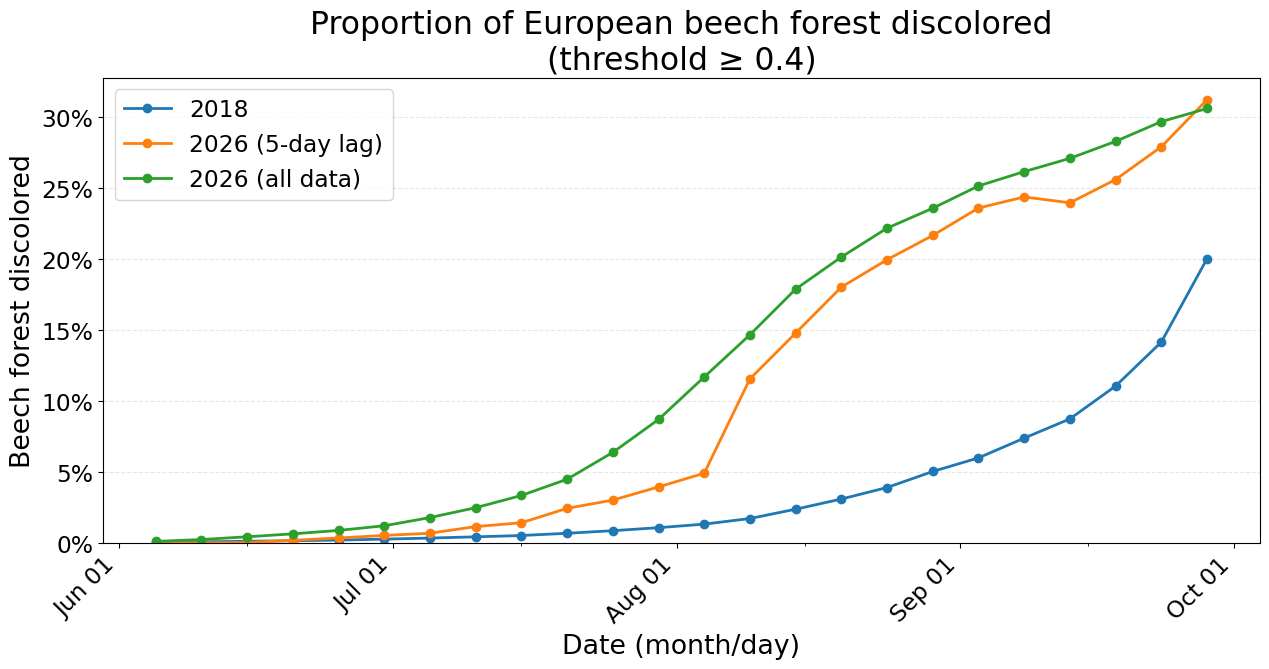

In [7]:
# Same plot as DiscoCH.ipynb, with the all-data series added
mosaics_2018 = r"B:\bloomc\JAG_Manuscript_2026_03_10\JAG_DiscoCH\output\disco_predictions\2026_03_21\mosaics"
threshold = 4000  # Stored value (0-10000) at/above which a pixel is discolored: 4000 = 40 % probability

comparison = plot_year_comparison(
    {
        "2018": dict(mosaic_dir=mosaics_2018, pattern="Proba_mosaic_*.tif", year=2018),
        f"{year} (5-day lag)": dict(mosaic_dir=nrt_masked, year=year),
        f"{year} (all data)": dict(mosaic_dir=full_masked, year=year),
    },
    threshold=threshold,
    output_dir=stats_output,
    output_name=f"discoloration_comparison_{year}_nrt_vs_full_data",
    max_workers=8,
)

In [6]:
# Difference per date: all data minus near real time
total = comparison[comparison.zone == "All"].pivot(index="date", columns="dataset", values="proportion")
diff = (total[f"{year} (all data)"] - total[f"{year} (5-day lag)"]).dropna()
print(diff.rename("all data - 5-day lag (proportion)").round(4).to_string())

date
2026-06-05    0.0010
2026-06-10    0.0023
2026-06-15    0.0041
2026-06-20    0.0046
2026-06-25    0.0053
2026-06-30    0.0068
2026-07-05    0.0110
2026-07-10    0.0133
2026-07-15    0.0192
2026-07-20    0.0205
2026-07-25    0.0336
2026-07-30    0.0475
2026-08-04    0.0678
2026-08-09    0.0311
2026-08-14    0.0310
2026-08-19    0.0212
2026-08-24    0.0222
2026-08-29    0.0192
2026-09-03    0.0156
2026-09-08    0.0179
2026-09-13    0.0313
2026-09-18    0.0269
2026-09-23    0.0177
2026-09-28   -0.0062
